# T6: Retrieval design study and proof of concept

This notebook is the design document and proof of concept (POC) for the brief's extrinsic evaluation (T6): *"a
retrieval/agent that starts at a coarse level and drills down to find target nodes, versus a flat baseline, scored on
hit-rate or steps-to-target"*. It does four things:

1. It studies the format of the questions (`data/questions.csv`) and the ground-truth answers
   (`data/ground_truth.json`) (§2–§3).
2. It maps the ground truth onto the graph and measures what the export can answer at all (§4).
3. It describes the coarsening hierarchy as a search index (§5).
4. It proposes a simple POC agent with a flat baseline (§6), defines the metrics (§7), runs both on all 18 questions
   (§8), and lists guidelines for the implementation (§9).

**Inputs:**
- the run configuration (`configs/default.toml` or `$TKH_CONFIG`);
- the graph export;
- the run's hierarchies, `out/<cutoff>/hierarchy.json`, which are read, never rebuilt;
- the two data files.

The POC functions are defined here on purpose: they are a reference for the rewrite, not the shipped module. Only
stable library code is imported (`tkh.io`, `tkh.semantic`, `tkh.config`, and the constant `CLUSTER_RELATIONS` from
`tkh.coarsen`). There are no LLM calls and no network.

**Scope.** The task is kept to building the agent and evaluating it:
- **retrieval targets:** methods, claims and citations. Type A answers with methods, their claims and citations; type B
  with claims and citations. GT method names are matched to graph nodes by exact name or acronym only;
- **evaluation:** hit-rate, error rate and steps-to-target, drill-down vs flat search (§7).

Everything left out is listed at the end as future work (§9).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "tkh").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from collections import Counter, defaultdict
import json
import re
import unicodedata

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import CountVectorizer

from tkh.coarsen import CLUSTER_RELATIONS
from tkh.config import load_config
from tkh.io import load, snapshot
from tkh import semantic as sm

print(f"python {sys.version.split()[0]}, pandas {pd.__version__}, matplotlib {matplotlib.__version__}")
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

cfg = load_config()  # honours $TKH_CONFIG
CUTOFFS, RUN, FIG = cfg.cutoffs, cfg.out_dir, cfg.figures_dir
FIG.mkdir(parents=True, exist_ok=True)
QUESTIONS, GT_PATH = ROOT / "data" / "questions.csv", ROOT / "data" / "ground_truth.json"
tkh = load(cfg)
H = {c: json.loads((RUN / str(c) / "hierarchy.json").read_text()) for c in CUTOFFS}
print(f"config: {cfg.source}\nrun: {RUN}\n{len(tkh.nodes)} nodes, {len(tkh.edges)} hyper-edges, "
      f"{len(tkh.articles)} articles; cutoffs {CUTOFFS}")

python 3.12.11, pandas 3.0.6, matplotlib 3.11.2
config: /Users/alexeyr/Personal/TKH/repo/configs/default.toml
run: /Users/alexeyr/Personal/TKH/repo/out
5798 nodes, 1429 hyper-edges, 52 articles; cutoffs (2020, 2022, 2024, 2026)


## 2. Questions: `data/questions.csv`

The file is `;`-separated with three columns: `question_id`, `question` and `type`. The type is metadata. A means
*specific search*: the answer is a list of methods (or datasets) plus their citations. B means *synthesis of
evidence*: the answer is a list of claims plus their citations.

The questions are written to a few templates. Most name an as-of date in parentheses ("by Feb 2026"). The cell below
parses, for each question:
- the template;
- the task phrase (after "for", before "when");
- the condition clause (after "when");
- the date cue.

In [2]:
qdf = pd.read_csv(QUESTIONS, sep=";", dtype=str)
print(qdf.shape, list(qdf.columns), dict(qdf["type"].value_counts()))

MONTHS = "jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec"
DATE = re.compile(rf"\b(?:by|as of|before|until|up to)\s+(?:(?:{MONTHS})[a-z]*\.?\s+)?((?:19|20)\d\d)\b", re.I)
TEMPLATES = [("which methods ... best suited for X [when Y]", r"^which methods .*best suited for "),
             ("what are the leading X", r"^what are the leading"),
             ("what datasets and benchmarks", r"^what datasets"),
             ("what are the most important open challenges", r"^what are the most important"),
             ("how does X improve Y", r"^how does"),
             ("give evidence that X", r"^give evidence"),
             ("what mechanisms ... and what evidence", r"^what mechanisms")]


def choose_snapshot(question, cutoffs=CUTOFFS):
    # Latest cutoff <= the stated year; no date -> the latest cutoff (the source is recorded).
    m = DATE.search(question)
    if not m:
        return max(cutoffs), None, "default_latest"
    year = int(m.group(1))
    ok = [c for c in sorted(cutoffs) if c <= year]
    return (ok[-1], year, "stated") if ok else (None, year, "before_first_cutoff")   # no snapshot: abstain


def parse(q):
    low = q.lower()
    tpl = next((name for name, rx in TEMPLATES if re.search(rx, low)), "other")
    task = re.search(r"\bfor (.+?)(?:\bwhen\b|\?|$)", re.sub(r"\([^)]*\)", "", q), re.I)
    cond = re.search(r"\bwhen (.+?)(?:\?|$)", q, re.I)
    date = re.search(r"\(([^)]*\d{4}[^)]*)\)", q)
    return tpl, task.group(1).strip() if task else "", cond.group(1).strip() if cond else "", date.group(1) if date else ""


rows = []
for _, r in qdf.iterrows():
    tpl, task, cond, date = parse(r["question"])
    snap, year, src = choose_snapshot(r["question"])
    rows.append({"id": r["question_id"], "type": r["type"], "words": len(r["question"].split()), "template": tpl,
                 "date cue": date, "as-of year": year, "snapshot": snap, "snapshot source": src,
                 "task phrase": task[:60], "condition": cond[:60]})
Q = pd.DataFrame(rows).set_index("id")
print("edge cases:", {t: choose_snapshot(t) for t in ("Which methods (by March 2023) work?", "Which methods by 2019?", "How does X work?")})
Q

(18, 3) ['question_id', 'question', 'type'] {'A': np.int64(14), 'B': np.int64(4)}
edge cases: {'Which methods (by March 2023) work?': (2022, 2023, 'stated'), 'Which methods by 2019?': (None, 2019, 'before_first_cutoff'), 'How does X work?': (2026, None, 'default_latest')}


,type,words,template,date cue,as-of year,snapshot,snapshot source,task phrase,condition
id,,,,,,,,,
Q1,A,27,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting interatomic potentials,balancing accuracy close to DFT with computational efficienc
Q2,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,accelerating electronic structure calculations,self-consistent field iterations become prohibitively expens
Q3,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,learning DFT Hamiltonians,dealing with twisted van der Waals heterostructures containi
Q4,A,21,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,phonon property prediction,universal MLIPs show inaccuracies despite good energy/force
Q5,A,22,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,coarse-graining molecular dynamics,crystalline symmetries and long-range elastic interactions m
Q6,A,25,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting ionic conductivity,full ab initio MD is too expensive but accuracy must be main
Q7,A,20,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting phase transitions,"screening ~50,000 inorganic compounds at high throughput"
Q8,A,22,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,predicting fracture patterns,generalizing from atomistic MD data to unseen bicrystalline
Q9,A,21,which methods ... best suited for X [when Y],by Feb 2026,2026.0,2026,stated,ensuring physical consistency,transferring information between scales without violating th


**Observations:**
- **Templates.** Q1–Q11 share one template, "which methods … best suited for <task> when <condition>"; Q11 has no
  condition. Q12–Q14 ask for the leading methods or datasets. Q15–Q18 are synthesis questions with four different
  templates.
- **Dates.** Every question but Q16 states "by Feb 2026". Q16 has no date cue, so it gets the latest snapshot, and
  this is recorded.
- **Snapshot granularity.** Snapshots are yearly (cutoffs 2020/2022/2024/2026). "Feb 2026" maps to the ≤2026
  snapshot, which cannot exclude papers published later in 2026; §4 checks how many there are.

**Design choice D1, snapshot rule:** the latest cutoff not after the stated year; no date → the latest cutoff; a date
before the first cutoff → no snapshot, so the agent abstains.
- Rationale: it never uses content after the question's date (P6), and it is deterministic.
- Rejected: always the latest snapshot, which would leak for earlier dates. Interpolating between snapshots isn't
  possible, because snapshots are cumulative and cut by year.
- Trade-off: within-year granularity is lost.

## 3. Ground truth: `data/ground_truth.json`

The file is a dict keyed by question id, and every entry has a `type`. The cells below inventory every field at every
nesting level, check the cross-references between fields, and assign each field a role in the evaluation.

In [3]:
gt = json.loads(GT_PATH.read_text())
A = {q: v for q, v in gt.items() if v["type"] == "A"}
B = {q: v for q, v in gt.items() if v["type"] == "B"}
assert set(gt) == set(qdf["question_id"]) and all(gt[q]["type"] == t for q, t in zip(qdf["question_id"], qdf["type"]))


def presence(entries):
    keys = sorted({k for v in entries for k in v})
    return pd.Series({k: sum(k in v for v in entries) for k in keys}, name=f"present in (of {len(entries)})")


print("type A, top level:"); display(presence(list(A.values())).to_frame())
print("type A, method_evidence items:"); display(presence([e for v in A.values() for m in v["method_evidence"].values() for e in m]).to_frame())
print("type A, fp_categories:"); display(presence([v["fp_categories"] for v in A.values() if "fp_categories" in v]).to_frame())
print("type B, top level:"); display(presence(list(B.values())).to_frame())
print("type B, required_claims items:"); display(presence([c for v in B.values() for c in v["required_claims"]]).to_frame())
print("type B, sources items:"); display(presence([s for v in B.values() for s in v["sources"].values()]).to_frame())

type A, top level:


,present in (of 14)
expected_methods,14
fp_categories,12
method_claims,14
method_evidence,14
required_citations,14
type,14


type A, method_evidence items:


,present in (of 188)
evidence,188
location,188
source,188


type A, fp_categories:


...

,present in (of 4)
as_of,4
contrast_sources,1
provenance_policy,1
required_citations,4
required_claims,4
sources,4
type,4


type B, required_claims items:


,present in (of 36)
caveat,23
contrast,1
coverage,36
distractor_note,7
evidence,36
flag,12
id,36
independence,6
locations,33
regime_scope,2


type B, sources items:


,present in (of 19)
date,19
doi,12
evidence_type,19
key,19
note,14
title,19
venue,19
verification,2
verified,5


In [4]:
def a_row(q, v):
    fp = v.get("fp_categories", {})
    return {"expected_methods": len(v["expected_methods"]), "method_claims": sum(map(len, v["method_claims"].values())),
            "method_evidence": sum(map(len, v["method_evidence"].values())), "required_citations": len(v["required_citations"]),
            "wrong_domain": len(fp.get("wrong_domain", [])), "outdated_as_main": len(fp.get("outdated_as_main", [])),
            "valid_but_unlisted": len(fp.get("valid_but_unlisted", [])), "has fp_categories": "fp_categories" in v}


def b_row(q, v):
    cl = v["required_claims"]
    return {"as_of": v["as_of"], "sources": len(v["sources"]), "required_claims": len(cl),
            **{f"coverage={c}": sum(x["coverage"] == c for x in cl) for c in ("full", "partial", "asserted_only")},
            "multi-source claims": sum(len(x["sources"]) > 1 for x in cl),
            "with independence": sum("independence" in x for x in cl), "with distractor_note": sum("distractor_note" in x for x in cl),
            "with contrast": sum("contrast" in x for x in cl), "required_citations": len(v["required_citations"]),
            "contrast_sources": len(v.get("contrast_sources", {}))}


display(pd.DataFrame({q: a_row(q, v) for q, v in A.items()}).T)
display(pd.DataFrame({q: b_row(q, v) for q, v in B.items()}).T)

,expected_methods,method_claims,method_evidence,required_citations,wrong_domain,outdated_as_main,valid_but_unlisted,has fp_categories
Q1,7,21,21,7,3,1,2,True
Q2,3,10,10,7,3,0,4,True
Q3,2,6,6,2,3,1,2,True
Q4,3,9,9,3,3,0,2,True
Q5,2,6,6,2,3,0,3,True
Q6,3,9,9,3,3,0,3,True
Q7,2,6,6,2,3,1,2,True
Q8,2,6,6,2,3,1,2,True
Q9,3,9,9,2,3,2,2,True
Q10,2,6,6,4,3,2,3,True


,as_of,sources,required_claims,coverage=full,coverage=partial,coverage=asserted_only,multi-source claims,with independence,with distractor_note,with contrast,required_citations,contrast_sources
Q15,2026-02,5,10,7,1,2,7,1,1,0,5,0
Q16,2026-02,4,9,8,1,0,3,1,3,0,4,0
Q17,2026-02,5,7,7,0,0,3,3,0,1,5,1
Q18,2026-02,5,10,9,1,0,5,1,3,0,5,0


In [5]:
# Cross-reference checks between fields (these define how the evaluator may join them)
checks = []
for q, v in A.items():
    em = set(v["expected_methods"])
    checks.append((q, "method_claims keys == expected_methods", set(v["method_claims"]) == em))
    checks.append((q, "method_evidence keys == expected_methods", set(v["method_evidence"]) == em))
    srcs = {e["source"] for m in v["method_evidence"].values() for e in m}
    checks.append((q, "evidence sources ⊆ required_citations", srcs <= set(v["required_citations"])))
    checks.append((q, "required_citations ⊆ evidence sources", set(v["required_citations"]) <= srcs))
    fp = {n for xs in v.get("fp_categories", {}).values() for n in xs}
    checks.append((q, "fp names disjoint from expected_methods", not (fp & em)))
for q, v in B.items():
    keys = set(v["sources"])
    checks.append((q, "required_citations ⊆ sources", set(v["required_citations"]) <= keys))
    checks.append((q, "claim sources ⊆ sources", all(set(c["sources"]) <= keys for c in v["required_claims"])))
    checks.append((q, "claim locations keyed by its sources",
                   all(set(c.get("locations", {})) <= set(c["sources"]) for c in v["required_claims"])))
    contrast = {s for c in v["required_claims"] for s in c.get("contrast", [])}
    checks.append((q, "claim contrast ⊆ contrast_sources", contrast <= set(v.get("contrast_sources", {}))))
ck = pd.DataFrame(checks, columns=["q", "check", "holds"])
display(ck.pivot_table(index="check", columns="holds", values="q", aggfunc=lambda s: ", ".join(s)).fillna(""))

holds,False,True
check,,
claim contrast ⊆ contrast_sources,,"Q15, Q16, Q17, Q18"
claim locations keyed by its sources,Q17,"Q15, Q16, Q18"
claim sources ⊆ sources,,"Q15, Q16, Q17, Q18"
evidence sources ⊆ required_citations,"Q2, Q3, Q9, Q11, Q12, Q13","Q1, Q4, Q5, Q6, Q7, Q8, Q10, Q14"
fp names disjoint from expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
method_claims keys == expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
method_evidence keys == expected_methods,,"Q1, Q2, Q3, Q4, Q5, Q6, Q7, Q8, Q9, Q10, Q11, Q12, Q13, Q14"
required_citations ⊆ evidence sources,"Q2, Q3, Q9, Q10, Q11, Q12, Q13","Q1, Q4, Q5, Q6, Q7, Q8, Q14"
required_citations ⊆ sources,,"Q15, Q16, Q17, Q18"


**What the cross-reference checks show:**
- **Method keys.** `method_claims` and `method_evidence` are keyed by exactly the `expected_methods`. The
  `fp_categories` names never overlap them.
- **Evidence sources (A).** The source strings in `method_evidence` are **not** always the strings in
  `required_citations` (7 of 14 questions differ):
  - the parenthetical hint is dropped ("Gong et al. 2023" vs "Gong et al. 2023 (DeepH-E3)");
  - several citations are joined with ";" ("Batzner et al. 2022; Batatia et al. 2022");
  - some sources are not papers ("Matbench Discovery leaderboard", "Orb-v3 Table 1");
  - spelling differs ("Schütt" vs "Schutt");
  - the *sets* differ too: a required citation with no evidence entry (Q10: Chen et al. 2019), and evidence citing
    papers missing from `required_citations` (Q12: Bochkarev et al. 2024, Fu et al. 2025; Q13: Barroso-Luque et
    al. 2024).
- **Consequence (applied in D3, §4):** the evaluator resolves each `;`-separated part of an evidence source on its own
  with the citation resolver (§4). It does not look the string up in `required_citations`. Non-paper sources are
  unattainable.
- **Type B.** Claim sources and `required_citations` are always keys of `sources`. In Q17, a claim's `locations` also
  names its `contrast` source (nan2024), which is a key of `contrast_sources`, not of `sources`.

In [6]:
# Example entries (type A method with its claims and evidence; type B claim with all annotations)
print(json.dumps({"Q3": {k: A["Q3"][k] for k in ("expected_methods", "fp_categories", "required_citations")}}, indent=1, ensure_ascii=False))
print(json.dumps(A["Q3"]["method_evidence"]["xDeepH"][0], indent=1, ensure_ascii=False))
c = next(c for c in B["Q17"]["required_claims"] if "contrast" in c)
print(json.dumps({k: (v[:160] + "…" if isinstance(v, str) and len(v) > 160 else v) for k, v in c.items()}, indent=1, ensure_ascii=False))
print("evidence_type of sources:", dict(Counter(s["evidence_type"] for v in B.values() for s in v["sources"].values())))

{
 "Q3": {
  "expected_methods": [
   "xDeepH",
   "DeepH-E3"
  ],
  "fp_categories": {
   "wrong_domain": [
    "MACE",
    "D4FT",
    "HamGNN"
   ],
   "outdated_as_main": [
    "DeepH (original, non-equivariant)"
   ],
   "valid_but_unlisted": [
    "DeepH-2",
    "DeepH-r"
   ]
  },
  "required_citations": [
   "Li et al. 2023 (xDeepH)",
   "Gong et al. 2023 (DeepH-E3)"
  ]
 }
}
{
 "source": "Li et al. 2023 (xDeepH)",
 "location": "Pages 1-2, workflow description",
 "evidence": "Extends DeepH to magnetic materials with E(3)×{I,T} equivariance using e3nn framework. Handles non-periodic magnetic superstructures (nanotubes, moiré structures)."
}
{
 "id": "Q17.C5",
 "text": "Demonstrated generality is bounded by the ansatz, not by data volume: structural assumptions exclude whole classes of observable that no additional training rem…",
 "coverage": "full",
 "sources": [
  "saxena2023"
 ],
 "contrast": [
  "nan2024"
 ],
 "locations": {
  "saxena2023": "Sec. 2 Eq. (3); Sec. 5.1 discussi

### Field roles in the evaluation

Every field gets one role. This project uses only the Option-A export (a design choice, not a requirement of the
brief). The export holds no paper text, so section-level `locations` cannot be checked against it. Under the POC scope
(methods, claims, citations), most annotation fields are **not used**; they are the material for future work (§9).

| Field | Type | Role in the POC | Rationale |
|---|---|---|---|
| `type` | A, B | **question metadata**, given to the agent | Type detection is not what T6 evaluates |
| `expected_methods` | A | **retrieval target** (method hit-rate, steps-to-target) | The answer list itself |
| `method_claims[m]` | A | **retrieval target** (method-claim hit-rate), matched by source article | What the answer should say about each method |
| `method_evidence[m].source` | A | **join**: a method → its source article(s), for method claims | Gives the method → paper link the graph must reproduce |
| `fp_categories.wrong_domain`, `.outdated_as_main` | A | **error signal**: returned items in these lists are errors | Penalises plausible but wrong answers |
| `fp_categories.valid_but_unlisted` | A | **neutral**: neither hit nor error | The ground truth is not exhaustive |
| `required_citations` | A, B | **retrieval target** (citation hit-rate) | Attribution is part of the answer |
| `sources[k].title`, `.doi` | B | **join**: a source key → a graph article (DOI first, then title) | The export mostly stores arXiv DOIs and the GT journal DOIs, so title matching does the work: of 19 sources, 13 resolve by title, 1 by DOI and 5 are not in the export (§4) |
| `required_claims[i].text` | B | **retrieval target** (claim hit-rate), matched by source article | The synthesis items |
| `required_claims[i].sources` | B | **join**: a claim → its source articles | A claim is hit through any of its sources |
| `as_of` | B | not used: the snapshot comes from the question text (§2) | Temporal compliance against `as_of` is future work |
| `method_evidence[m].evidence`, `required_claims[i].evidence` | A, B | not used: content for a semantic judge | Paraphrase/quote of the paper |
| `method_evidence[m].location`, `required_claims[i].locations` | A, B | not scorable from the export | Section/page of the paper |
| `required_claims[i].coverage`, `sources[k].evidence_type` | B | not used: candidate stratifiers | — |
| `required_claims[i].independence`, `.distractor_note`, `.contrast`, `contrast_sources` | B | not used: multi-source, negative and contrast checks | — |
| `required_claims[i].id`, `.caveat`, `.flag`, `.regime_scope`; `sources[k].key`, `.date`, `.venue`, `.note`, `.verified`, `.verification`; `provenance_policy` | B | display, grader guidance or curation metadata | Describe how the GT was built or how prose should be worded |

## 4. Mapping the ground truth onto the graph (attainability)

The evaluator, never the agent, resolves each ground-truth item to nodes of the question's snapshot. An item that does
not resolve is **unattainable**: the graph does not contain it, so no retriever can find it. Hit-rates are computed
over attainable items, and the shares that are attainable are reported as **ceilings**. This keeps graph coverage
separate from retrieval failure.

**Design choice D2, method resolution.** Two rules; the first that matches wins:
1. **exact** `name_key` match on the surface form or an alias;
2. **acronym:** the name inside parentheses ("GAP" → "Gaussian approximation potential (GAP) for silicon").

Looser rules were left out. A prefix rule ("Orb" → "Orb-v2") adds a few matches but merges model versions;
substring matching is too loose ("ACE" would match "surfACE").

**Design choice D3, citation resolution.** `authored_by` hyper-edges list authors *in no particular order*, so
"First author et al. YYYY" cannot be matched literally. A citation matches articles whose author set contains every
surname it names (diacritics folded), with the year within ±1 (preprint vs journal year) and the exact year
preferred. A parenthetical hint ("Li et al. 2022 (DeepH)") narrows ambiguous candidates by title or presented method.
Type-B sources resolve by DOI first, then by title. In practice title matching does the work: 36 of 52 articles have
a provenance DOI, mostly arXiv DOIs, while the GT gives journal DOIs. Only one source (Q18, jacobs2025) resolves by
DOI.

**Method claims (A)** are attainable only if the graph holds a claim on the same `claims` hyper-edge as a resolved node
of the method, from one of the method's evidence articles. A resolvable citation alone is not enough (two columns in
the table below).

In [7]:
KINDS = {"A": ("method", "technique", "component", "dataset"),   # expected_methods also lists datasets/benchmarks (Q14)
         "B": ("claim",)}
YEAR = re.compile(r"\b((?:19|20)\d\d)\b")


def fold(s):
    return "".join(ch for ch in unicodedata.normalize("NFKD", str(s)) if not unicodedata.combining(ch)).lower()


class Snap:
    # One snapshot's graph facts for the evaluator and the agent (no hierarchy, no text model).
    def __init__(self, cutoff):
        s = snapshot(tkh, cutoff)
        self.cutoff, self.s = cutoff, s
        self.ids = sorted(s.node_ids)
        self.type = tkh.nodes["type"].to_dict()
        self.name = {v: sm.clean(x) for v, x in tkh.nodes["surface_form"].items()}
        self.keys = sm.name_keys(tkh)
        prov = tkh.nodes["prov_articles"].to_dict()
        self.articles_of = {v: [a for a in prov[v] if a in s.articles] for v in self.ids}
        arts = tkh.articles
        self.year = {a: int(y) for a, y in arts["year"].items() if a in s.articles}
        self.title = {a: sm.clean(t) for a, t in arts["title"].items() if a in s.articles and isinstance(t, str)}
        node_of = arts["node_id"].to_dict()
        self.doi = {a: str((tkh.nodes.at[node_of[a], "provenance"] or {}).get("doi") or "").lower()
                    for a in s.articles if isinstance(node_of.get(a), str)}
        self.authors, self.presents, self.claims_of = defaultdict(list), defaultdict(list), defaultdict(list)
        for m, r, a in zip(s.edges["members"], s.edges["relation_type"], s.edges["article_id"]):
            if r == "authored_by":
                self.authors[a] += [self.name[v] for v in m[1:]]
            elif r == "presents":
                self.presents[a] += m[1:]
            elif r == "claims":
                self.claims_of[a] += [v for v in m[1:] if self.type[v] == "claim"]
        self.method_claims = defaultdict(set)          # method node -> claim nodes on the same claims edge
        for m, r in zip(s.edges["members"], s.edges["relation_type"]):
            if r == "claims":
                cl = [v for v in m[1:] if self.type[v] == "claim"]
                for v in m[1:]:
                    if self.type[v] != "claim":
                        self.method_claims[v].update(cl)

    def citation(self, a):
        sur = [sm.clean(n).split(" ")[-1] for n in self.authors.get(a, [])]
        who = sur[0] if len(sur) == 1 else f"{sur[0]} & {sur[1]}" if len(sur) == 2 else f"{sur[0]} et al." if sur else "Anon."
        return f"{who} {self.year[a]}"


SNAP = {c: Snap(c) for c in CUTOFFS}


def resolve_method(name, S, kinds=KINDS["A"]):
    want = sm.name_key(name)
    cand = [v for v in S.ids if S.type[v] in kinds]
    tiers = [("exact", lambda v: want in S.keys[v]),
             ("acronym", lambda v: want in {sm.name_key(p) for p in re.findall(r"\(([^)]*)\)", S.name[v])})]
    for tier, ok in tiers:
        hit = [v for v in cand if want and ok(v)]
        if hit:
            return tier, hit
    return "unattainable", []


def parse_citation(c):
    hint = re.search(r"\(([^)]*)\)\s*$", c)
    y = YEAR.search(c)
    who = re.sub(r"\bet al\.?", "", c[:y.start()] if y else c)
    names = [fold(x.strip().split(" ")[-1]) for x in re.split(r"&|\band\b|,", who) if x.strip()]
    return names, int(y.group(1)) if y else None, hint.group(1) if hint else None


def resolve_citation(c, S):
    names, year, hint = parse_citation(c)
    if not names or year is None:
        return "unattainable", []
    sur = {a: {fold(sm.clean(n).split(" ")[-1]) for n in S.authors.get(a, [])} for a in S.year}
    cand = [a for a in S.year if abs(S.year[a] - year) <= 1 and set(names) <= sur[a]]
    cand = [a for a in cand if S.year[a] == year] or cand
    if hint and len(cand) > 1:
        h = sm.name_key(hint)
        cand = [a for a in cand if h in sm.name_key(S.title.get(a, "")) or
                any(h in sm.name_key(S.name[v]) for v in S.presents.get(a, ()))] or cand
    return ("unattainable" if not cand else "unique" if len(cand) == 1 else "ambiguous"), sorted(cand)


def _words(s):
    return set(re.findall(r"[a-z0-9]+", fold(s)))


def resolve_source(src, S):
    doi = str(src.get("doi") or "").lower()
    hit = [a for a, d in S.doi.items() if doi and d == doi]
    if hit:
        return "doi", hit
    t, tw = sm.name_key(src.get("title", "")), _words(src.get("title", ""))
    hit = [a for a, title in S.title.items()
           if sm.name_key(title) == t or len(tw & _words(title)) / max(1, len(tw | _words(title))) >= 0.8]
    return ("title" if hit else "unattainable"), sorted(hit)

In [8]:
def resolve_gold(qid):
    # Every ground-truth item of one question -> graph nodes / articles, with its tier.
    v, S = gt[qid], SNAP[Q.loc[qid, "snapshot"]]
    g = {"qid": qid, "type": v["type"]}
    if v["type"] == "A":
        g["methods"] = {m: dict(zip(("tier", "nodes"), resolve_method(m, S))) for m in v["expected_methods"]}
        g["citations"] = {c: dict(zip(("tier", "articles"), resolve_citation(c, S))) for c in v["required_citations"]}
        fp = v.get("fp_categories", {})
        g["fp"] = {cat: {n: resolve_method(n, S)[1] for n in fp[cat]} for cat in ("wrong_domain", "outdated_as_main") if cat in fp}
        # per-method claims, grounded in the method's evidence sources
        g["method_claims"] = []
        for m, claims in v["method_claims"].items():
            arts = sorted({a for e in v["method_evidence"][m] for part in e["source"].split(";")
                           for a in resolve_citation(part.strip(), S)[1]})
            attainable = any(set(S.articles_of[x]) & set(arts) for n in g["methods"][m]["nodes"] for x in S.method_claims[n])
            for text in claims:
                g["method_claims"].append({"method": m, "text": text, "articles": arts, "source_resolves": bool(arts),
                                           "attainable": attainable})
        g["step_items"] = [r["nodes"] for r in g["methods"].values() if r["nodes"]]   # one per attainable GT method
    else:
        src = {k: dict(zip(("tier", "articles"), resolve_source(s, S))) for k, s in v["sources"].items()}
        g["sources"] = src
        g["citations"] = {k: src[k] for k in v["required_citations"]}
        g["claims"] = []
        for c in v["required_claims"]:
            arts = sorted({a for k in c["sources"] for a in src[k]["articles"] if S.claims_of[a]})
            g["claims"].append({"id": c["id"], "articles": arts, "attainable": bool(arts),
                                "nodes": sorted({x for a in arts for x in S.claims_of[a]})})
        g["step_items"] = [c["nodes"] for c in g["claims"] if c["attainable"]]   # one per attainable required claim
    g["targets"] = sorted({x for it in g["step_items"] for x in it})
    return g


GOLD = {q: resolve_gold(q) for q in gt}


def ceiling_row(g):
    if g["type"] == "A":
        tiers = Counter(r["tier"] for r in g["methods"].values())
        return {"methods": f"{sum(bool(r['nodes']) for r in g['methods'].values())}/{len(g['methods'])}",
                "by exact name": tiers["exact"], "by acronym": tiers["acronym"],
                "citations": f"{sum(bool(r['articles']) for r in g['citations'].values())}/{len(g['citations'])}",
                "ambiguous citations": sum(r["tier"] == "ambiguous" for r in g["citations"].values()),
                "method claims: source resolves": f"{sum(c['source_resolves'] for c in g['method_claims'])}/{len(g['method_claims'])}",
                "method claims: graph claim exists": f"{sum(c['attainable'] for c in g['method_claims'])}/{len(g['method_claims'])}",
                "target nodes": len(g["targets"])}
    return {"claims": f"{sum(c['attainable'] for c in g['claims'])}/{len(g['claims'])}",
            "citations": f"{sum(bool(r['articles']) for r in g['citations'].values())}/{len(g['citations'])}",
            "sources by doi": sum(r["tier"] == "doi" for r in g["sources"].values()), "target nodes": len(g["targets"])}


display(pd.DataFrame({q: ceiling_row(g) for q, g in GOLD.items() if g["type"] == "A"}).T)
display(pd.DataFrame({q: ceiling_row(g) for q, g in GOLD.items() if g["type"] == "B"}).T)
print("unattainable methods:", sorted({m for g in GOLD.values() if g["type"] == "A" for m, r in g["methods"].items() if not r["nodes"]}))
print("unattainable B sources:", sorted({k for g in GOLD.values() if g["type"] == "B" for k, r in g["sources"].items() if not r["articles"]}))

,methods,by exact name,by acronym,citations,ambiguous citations,method claims: source resolves,method claims: graph claim exists,target nodes
Q1,7/7,5,2,7/7,1,21/21,12/21,15
Q2,2/3,2,0,7/7,1,10/10,3/10,3
Q3,2/2,2,0,2/2,1,6/6,0/6,2
Q4,1/3,1,0,3/3,0,9/9,3/9,2
Q5,0/2,0,0,1/2,0,3/6,0/6,0
Q6,1/3,1,0,3/3,0,9/9,3/9,1
Q7,1/2,1,0,2/2,0,6/6,0/6,1
Q8,1/2,1,0,2/2,0,6/6,0/6,1
Q9,1/3,1,0,2/2,1,9/9,3/9,2
Q10,1/2,1,0,4/4,0,6/6,3/6,1


,claims,citations,sources by doi,target nodes
Q15,6/10,2/5,0,25
Q16,9/9,4/4,0,48
Q17,7/7,4/5,0,65
Q18,10/10,4/5,1,101


unattainable methods: ['AFLOW', 'Bead-mapping', 'CE→MC→NN→PF', 'DeePMD+AL', 'E(3)-equivariant GNNs', 'GNN free energies', 'GNN stress fields', 'GNN+GPP', 'GNNs + ACE descriptors', 'HamGNN', 'Hessian training', 'MACE-F', 'MLIP descriptors', 'Orb', 'PET', 'UMA', 'hybrid frameworks', 'physics-informed']
unattainable B sources: ['deng2025_softening', 'geiger2022', 'jakob2025', 'li2025_ood', 'turchyna2025']


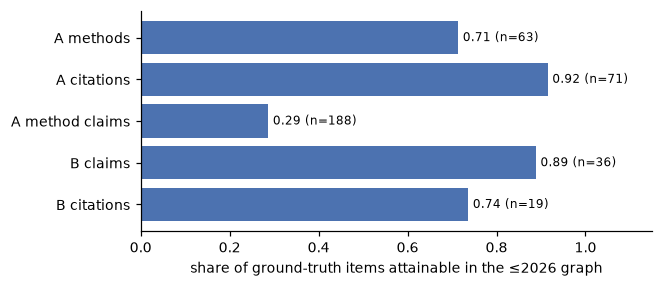

ceilings: {'A methods': 0.714, 'A citations': 0.915, 'A method claims': 0.287, 'B claims': 0.889, 'B citations': 0.737}
articles dated 2026 in the ≤2026 snapshot (not excludable for 'by Feb 2026' with yearly snapshots): 6


In [9]:
def frac(items, key):
    items = list(items)
    return sum(bool(key(x)) for x in items) / max(1, len(items)), len(items)


kinds = {"A methods": [r for g in GOLD.values() if g["type"] == "A" for r in g["methods"].values()],
         "A citations": [r for g in GOLD.values() if g["type"] == "A" for r in g["citations"].values()],
         "A method claims": [c for g in GOLD.values() if g["type"] == "A" for c in g["method_claims"]],
         "B claims": [c for g in GOLD.values() if g["type"] == "B" for c in g["claims"]],
         "B citations": [r for g in GOLD.values() if g["type"] == "B" for r in g["citations"].values()]}
keyf = {"A methods": lambda r: r["nodes"], "A citations": lambda r: r["articles"], "A method claims": lambda c: c["attainable"],
        "B claims": lambda c: c["attainable"], "B citations": lambda r: r["articles"]}
ceil = {k: frac(v, keyf[k]) for k, v in kinds.items()}
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(list(ceil), [f for f, _ in ceil.values()], color="#4c72b0")
for i, (f, n) in enumerate(ceil.values()):
    ax.text(f + 0.01, i, f"{f:.2f} (n={n})", va="center", fontsize=8)
ax.set_xlim(0, 1.15); ax.invert_yaxis(); ax.set_xlabel("share of ground-truth items attainable in the ≤2026 graph")
fig.savefig(FIG / "t6_attainability.png"); plt.show()
print("ceilings:", {k: round(f, 3) for k, (f, _) in ceil.items()})
print("articles dated 2026 in the ≤2026 snapshot (not excludable for 'by Feb 2026' with yearly snapshots):",
      sum(y == 2026 for y in SNAP[2026].year.values()))

**Outcome of §4:**
- The ceilings are well below 1 (printed above). Some GT methods are conceptual names ("physics-informed", "hybrid
  frameworks") or specific methods absent from the export (e.g. HamGNN); exact + acronym matching also leaves out
  versioned names ("Orb" for "Orb-v2"). Several type-B sources are not among the export's papers.
- Method claims are the scarcest target: a graph claim from the method's evidence article must be attached to the
  method.
- Hit-rates in §8 are over attainable items only, so they measure retrieval, not graph coverage.

## 5. The hierarchy as a search index

The coarsening algorithm writes, per snapshot, a laminar tree:
- L0 has 15 super-nodes, L1 60, L2 240 (P2 budgets);
- L0–L1 super-nodes carry an LLM label and gloss (P6), L2 has none;
- every leaf (graph node) sits in exactly one L2 super-node (P1).

A drill-down agent can only reach targets whose ancestors it keeps. The **target dispersion** below counts, per
question, how many super-nodes at each level hold at least one target. That count is the smallest beam that could keep
all targets if the ranking were perfect: an **oracle bound**.

This diagnostic reads the ground-truth targets directly, so it is for understanding only. The beam (D6) was selected
on these questions' hit-rates, which is itself in-sample (D5).

          2020  2022  2024  2026
L0          15    15    15    15
L1          60    60    60    60
L2         240   240   240   240
labelled    75    75    75    75
leaves    1475  2144  4094  5798
leaves of the answer kinds at ≤2026: {'A': 2524, 'B': 690}


,Q1,Q2,Q3,Q4,Q6,Q7,Q8,Q9,Q10,Q12,Q13,Q14,Q15,Q16,Q17,Q18
L0,5,2,1,1,1,1,1,1,1,6,7,7,2,3,3,4
L1,9,2,2,2,1,1,1,2,1,9,11,11,2,3,4,4
L2,10,3,2,2,1,1,1,2,1,11,12,14,2,3,4,4
targets,15,3,2,2,1,1,1,2,1,20,18,21,25,48,65,101


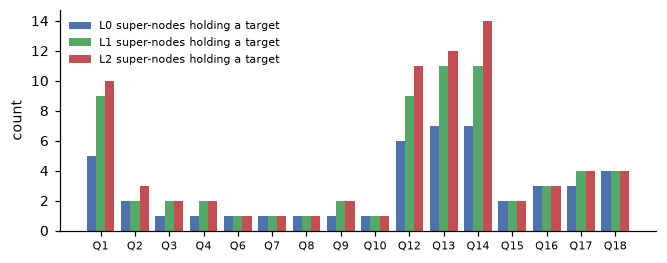

In [10]:
def tree(c):
    h = H[c]
    sn = {s["id"]: s for s in h["supernodes"]}
    children = defaultdict(list)
    for s in h["supernodes"]:
        if s["parent_id"] is not None:
            children[s["parent_id"]].append(s["id"])
    return sn, children


print(pd.DataFrame({c: {f"L{k}": sum(s["level"] == k for s in H[c]["supernodes"]) for k in range(H[c]["levels"])}
                    | {"labelled": sum(bool(s.get("label")) for s in H[c]["supernodes"]),
                       "leaves": len({v for s in H[c]["supernodes"] if s["level"] == 2 for v in s["member_ids"]})}
                    for c in CUTOFFS}))
S26 = SNAP[2026]
print("leaves of the answer kinds at ≤2026:", {t: sum(S26.type[v] in KINDS[t] for v in S26.ids) for t in KINDS})

sn26, _ = tree(2026)
disp = {}
for q, g in GOLD.items():
    t = set(g["targets"])
    if t:
        disp[q] = {f"L{k}": sum(bool(t & set(s["member_ids"])) for s in sn26.values() if s["level"] == k) for k in range(3)}
        disp[q]["targets"] = len(t)
D = pd.DataFrame(disp).T
display(D.T)
fig, ax = plt.subplots(figsize=(7, 2.6))
x = np.arange(len(D))
for k, (lv, col) in enumerate(zip(("L0", "L1", "L2"), ("#4c72b0", "#55a868", "#c44e52"))):
    ax.bar(x + (k - 1) * 0.27, D[lv], width=0.27, label=f"{lv} super-nodes holding a target", color=col)
ax.set_xticks(x, D.index, fontsize=7); ax.set_ylabel("count"); ax.legend(fontsize=7, frameon=False)
fig.savefig(FIG / "t6_target_dispersion.png"); plt.show()

**Reading the dispersion results.** Two regimes appear:
- **Dispersed questions** (Q1, Q2, Q12–Q14 and the synthesis questions Q15–Q18) have targets in 2–7 L0 super-nodes. For
  these, a small L0 beam cannot keep every target even with a perfect ranking, so the coarse grouping by use case
  matters. Intrinsically, coherence at L0 is not supported (`docs/evaluation_report.md` §3).
- **Narrow type-A questions** (Q3, Q4, Q6–Q10) have their 1–2 targets inside a single L0 super-node. A beam reaches
  them only *if the right L0 and L1 nodes rank in the beam*. For these, reach depends on the routing score, not on
  dispersion.

Q5 and Q11 have no attainable targets and are left out. Recall should not be the only metric; steps and cost
matter too (§7).

## 6. POC agent: drill-down beam search and flat baseline

**Design choice D4, node content.** All of it is built from the snapshot's own edges (P6).
- **Leaf text:**
  - name and aliases;
  - the names of its relation neighbours over the clustering relations (`addresses`, `solves`, `extends`,
    `uses_component`, `uses_technique`, `evaluated_on`);
  - the `evaluated_on` metric and task;
  - the title of the article that presents it (method, **once**) or claims it (claim);
  - for a presented method, its paper's claims.
- **Super-node content:** label + gloss (L0–L1) and the centroid of its members' leaf vectors.
- `tkh.semantic.attached_text` is not used: it reads all edges of the export, which would leak later facts into
  earlier snapshots.

**Design choice D5, similarity: keyword overlap.** A text's score is the share of the question's keywords (those in the
snapshot's leaf vocabulary) that it contains. Keywords are word tokens (hyphens and `+` kept, so "DeepH-E3" stays one token), with English stop words and
the template words removed; the vocabulary is fitted per snapshot on leaf texts only. Texts and the question are
binary keyword vectors, and the question vector is divided by its keyword count.
- **Selection.** The scorer, the beam (D6), the content choices (D4, D6) and the question encoding (template words
  stripped) are the configuration that scored best in a staged experiment series of 55 configurations on these
  questions. It varied beam widths and relative thresholds; super-node content (label, centroid, both, per-kind
  centroid, document text); leaf content (name only, with relations, full, full plus the presenting paper's claims);
  the scorer (TF-IDF cosine, BM25, keyword overlap); and the question text (full, stripped, task or condition phrase
  only).
  - The objective was the drill-down's mean, over the 16 questions with attainable targets, of (item hit-rate +
    citation hit-rate) / 2. Ties within 0.01 were broken by the lower *mean* censored steps-to-target, a statistic §7
    does not report.
  - Keyword overlap beat TF-IDF and BM25 on that objective.
  - The series scored items with an earlier version of the gold resolution, so its values differ in detail from §8,
    which prints the same objective under §7's scoring.
  - The selection is in-sample, so §8 is an optimistic estimate (§9).
- **A plausible reading, not tested here:** the questions are short and use the graph's own terms ("Hamiltonian",
  "equivariant"). TF-IDF down-weights terms shared by many leaves, and BM25 also penalises long leaf texts, while
  overlap counts each question keyword once.
- Clustering used a char-n-gram LSA of names, so this is a different ruler. It is not independent, though: names and
  clustering-relation neighbours are inside the leaf text. That partial overlap is stated, not hidden.
- An embedding model would be stronger on paraphrase, but it is a new dependency and download (rejected for the POC).

**Design choice D6, drill-down.**
- L0–L1 super-node score = 0.5·s(q, label + gloss) + 0.5·s(q, centroid); L2 score = s(q, centroid). The centroid
  is the share of the super-node's members that contain each keyword.
- Beam widths (10, 20, 40) for 15 / 60 / 240 super-nodes, the selected setting (D5). Narrower beams (down to 1 / 1 / 1)
  reached fewer questions; the widest tried (15 / 30 / 60) scored within 0.01 on the objective and lost on the mean steps tie-break, so
  10 / 20 / 40 vs 15 / 30 / 60 is a near-tie, not a robust difference. Relative
  thresholds (keep children scoring ≥ a share of the level's best) were worse at every setting tried.
- The pool is the leaves of the kept L2 super-nodes that have the answer kinds, ranked by s(q, leaf).
- **Consequence, measured in §8:** L0 keeps 10 of 15 nodes (0.67); L1 and L2 then keep about half of their frontier.
  Pruning is spread over the three levels, and the drill-down scores about 130–160 super-nodes per question.
- The question is stripped of template words and the date clause before encoding.

**Design choice D7, flat baseline.** The same scorer, leaf texts and answer kinds over every leaf. Only the search
differs, so any difference is the hierarchy's.

**Design choice D8, answer format.** The ground-truth format with k = 10 items, plus the node and article ids the
answer was read from (so scoring needs no string matching):
- **A:** `expected_methods`, `required_citations`, plus `method_claims` and `method_evidence` per returned method,
  read from up to 3 graph claims attached to it (by node id);
- **B:** `as_of`, `required_claims`, `sources` and `required_citations`.

In [11]:
TEMPLATE = re.compile(r"\((?:by|as of)[^)]*\)|\b(?:which|what|are|is|the|methods?|best|suited|leading|most|"
                      r"important|commonly|used|give|evidences?|when|for|of|by|feb|\d{4})\b", re.I)
BEAM, K = (10, 20, 40), 10      # selected configuration (see §6, D6)


def leaf_texts(S):
    name, title = sm.names(tkh), tkh.articles["title"].to_dict()
    txt = {v: [name[v]] for v in S.ids}
    attrs = S.s.edges["attributes"] if "attributes" in S.s.edges else [None] * len(S.s.edges)
    presented = {}
    for m, r, a, at in zip(S.s.edges["members"], S.s.edges["relation_type"], S.s.edges["article_id"], attrs):
        if r in CLUSTER_RELATIONS:
            txt[m[0]] += [name[t] for t in m[1:]]
            for t in m[1:]:
                txt[t].append(name[m[0]])
            if r == "evaluated_on" and isinstance(at, dict):
                for v in m:
                    txt[v].append(" ".join(str(at[k]) for k in ("metric", "task") if at.get(k)))
        elif r == "presents" and isinstance(title.get(a), str):
            txt[m[1]].append(sm.clean(title[a]))             # once per presented method
            presented[a] = m[1]
        elif r == "claims" and isinstance(title.get(a), str):
            for v in m[1:]:
                if S.type[v] == "claim":
                    txt[v].append(sm.clean(title[a]))
    for a, v in presented.items():
        txt[v] += [S.name[c] for c in S.claims_of[a]]
    return {v: " . ".join(x) for v, x in txt.items()}


def binary(C):
    C = sp.csr_matrix(C, dtype=float)
    C.data[:] = 1.0
    return C


class Index:
    # Snapshot search index: binary leaf keyword vectors, super-node label and centroid vectors, the tree.
    def __init__(self, cutoff):
        self.S = SNAP[cutoff]
        sn, self.children = tree(cutoff)
        self.sn = sn
        self.roots = [i for i, s in sn.items() if s["level"] == 0]
        self.leaves = sorted({v for s in sn.values() if s["level"] == 2 for v in s["member_ids"]})
        texts = leaf_texts(self.S)
        self.vec = CountVectorizer(lowercase=True, stop_words="english", token_pattern=r"(?u)\b[\w][\w\-\+]*\b")
        self.X = binary(self.vec.fit_transform([texts[v] for v in self.leaves]))
        self.row = {v: i for i, v in enumerate(self.leaves)}
        self.centroid = {i: np.asarray(self.X[[self.row[v] for v in s["member_ids"]]].mean(axis=0))[0]
                         for i, s in sn.items()}     # share of members containing each keyword
        lab = [i for i, s in sn.items() if s.get("label")]
        L = binary(self.vec.transform([sm.clean(f"{sn[i]['label']} . {sn[i].get('gloss') or ''}") for i in lab]))
        self.labelvec = {i: L[j].toarray()[0] for j, i in enumerate(lab)}

    def encode(self, question):
        # binary question keywords / their count: a text's score is the share of question keywords it contains
        q = (self.vec.transform([sm.clean(TEMPLATE.sub(" ", question))]).toarray()[0] > 0).astype(float)
        return q / max(1.0, q.sum())

    def score(self, i, q):
        c = float(self.centroid[i] @ q)
        return 0.5 * float(self.labelvec[i] @ q) + 0.5 * c if i in self.labelvec else c

    def rank(self, ids, q):
        ids = sorted(ids)
        s = self.X[[self.row[v] for v in ids]] @ q if ids else np.zeros(0)
        return sorted(zip(ids, map(float, s)), key=lambda t: (-t[1], t[0]))


def descend(ix, q, kinds, beam=BEAM):
    frontier, trace = ix.roots, []
    for level, b in enumerate(beam):
        scored = sorted(((ix.score(i, q), i) for i in frontier), key=lambda t: (-t[0], t[1]))
        keep = [i for _, i in scored[:b]]
        trace += [{"level": level, "id": i, "label": ix.sn[i].get("label"), "score": round(s, 4), "kept": i in keep}
                  for s, i in scored]
        frontier = [c for i in keep for c in ix.children[i]]
    pool = {v for i in keep for v in ix.sn[i]["member_ids"] if ix.S.type[v] in kinds}
    return ix.rank(pool, q), trace


def flat(ix, q, kinds):
    return ix.rank([v for v in ix.leaves if ix.S.type[v] in kinds], q), []

In [12]:
def extract(S, qtype, ranked, as_of):
    # The answer in the ground-truth format, plus the ids it was read from.
    if qtype == "A":
        seen, picked = set(), []
        for v, _ in ranked:
            k = sm.name_key(S.name[v])
            if k and k not in seen:
                seen.add(k); picked.append(v)
            if len(picked) == K:
                break
        claims = {S.name[v]: sorted(S.method_claims[v])[:3] for v in picked}
        arts = list(dict.fromkeys(a for v in picked for a in S.articles_of[v]))
        return {"expected_methods": [S.name[v] for v in picked],
                "method_claims": {m: [S.name[c] for c in cs] for m, cs in claims.items()},
                "method_evidence": {m: [{"source": S.citation(a), "location": c, "evidence": S.name[c]}
                                        for c in cs for a in S.articles_of[c][:1]] for m, cs in claims.items()},
                "required_citations": [S.citation(a) for a in arts],
                "_nodes": picked, "_claim_nodes": {S.name[v]: cs for v, cs in zip(picked, claims.values())}, "_articles": arts}
    picked = [v for v, _ in ranked[:K]]
    arts = list(dict.fromkeys(a for v in picked for a in S.articles_of[v]))
    key = {a: f"{fold(S.citation(a).split(' ')[0])}{S.year[a]}_{a}" for a in arts}
    return {"as_of": as_of,
            "required_claims": [{"id": f"R{i + 1}", "text": S.name[v], "sources": [key[a] for a in S.articles_of[v]]}
                                for i, v in enumerate(picked)],
            "sources": {key[a]: {"key": S.citation(a), "title": S.title.get(a), "date": str(S.year[a])} for a in arts},
            "required_citations": [key[a] for a in arts], "_nodes": picked, "_articles": arts}


class Agent:
    # answer(question, qtype, mode): sees only the question text and its type.
    def __init__(self, index_for=None, beam=BEAM):
        self.ix, self.beam = index_for or {}, beam

    def index(self, c):
        if c not in self.ix:
            self.ix[c] = Index(c)
        return self.ix[c]

    def answer(self, question, qtype, mode="hier"):
        c, year, _ = choose_snapshot(question)
        if c is None:                                    # date before the first cutoff: no admissible snapshot
            return {"abstain": True, "snapshot": None}
        ix = self.index(c)
        q = ix.encode(question)
        ranked, trace = descend(ix, q, KINDS[qtype], self.beam) if mode == "hier" else flat(ix, q, KINDS[qtype])
        out = extract(ix.S, qtype, ranked, f"{year or c}")
        out.update(snapshot=c, ranked=[v for v, _ in ranked], trace=trace, n_scored=len(trace),
                   closest={lv: next((t["id"], t["label"], t["score"]) for t in trace if t["level"] == lv)
                            for lv in sorted({t["level"] for t in trace})})
        if ranked:
            out["closest"]["leaf"] = (ranked[0][0], ix.S.name[ranked[0][0]], round(ranked[0][1], 4))
        return out


agent = Agent()
for qid in ("Q2", "Q15"):
    a = agent.answer(qdf.set_index("question_id").loc[qid, "question"], gt[qid]["type"])
    print(f"{qid} -> snapshot {a['snapshot']}; super-nodes scored {a['n_scored']}; pool {len(a['ranked'])}")
    for lv, (i, lab, s) in a["closest"].items():
        print(f"   closest at {'L' + str(lv) if lv != 'leaf' else 'leaf'}: {i} {lab!r} ({s})")
    show = a["expected_methods"] if gt[qid]["type"] == "A" else [c["text"][:90] for c in a["required_claims"]]
    print("   answer:", show[:5], "\n   citations:", a["required_citations"][:5])

Q2 -> snapshot 2026; super-nodes scored 150; pool 376
   closest at L0: L0.9 'High-throughput DFT methods' (0.0465)
   closest at L1: L1.59 'Density functional techniques' (0.1171)
   closest at L2: L2.193 None (0.1197)
   closest at leaf: meth_00222 'D4FT' (0.7692)
   answer: ['D4FT', 'Comprehensive review of AI-driven multiscale modeling approaches for solid-state physics and chemistry', 'DeepH-E3', 'deep equivariant neural network method', 'deep neural network approach to represent DFT Hamiltonian'] 
   citations: ['Lin et al. 2023', 'Maevskiy et al. 2026', 'Xu et al. 2022', 'Xu et al. 2023', 'Xu et al. 2022']
Q15 -> snapshot 2026; super-nodes scored 145; pool 203
   closest at L0: L0.8 'Graph Neural Networks' (0.1055)
   closest at L1: L1.54 'Uncertainty Quantification Techniques' (0.1623)
   closest at L2: L2.184 None (0.2857)
   closest at leaf: clai_00357 'Current challenges limiting AI-driven multiscale modeling include limited data availability, restricted model transferabilit

In [13]:
# P6 check on an earlier snapshot (all 18 questions use ≤2026, so this exercises the temporal path explicitly):
# a method published after 2020 that extends a ≤2020 node must not appear in that node's ≤2020 text or vocabulary.
S20, S26 = SNAP[2020], SNAP[2026]
t20, t26 = leaf_texts(S20), leaf_texts(S26)
late = S26.s.edges[(S26.s.edges["article_year"] > 2020) & (S26.s.edges["relation_type"] == "extends")]
pairs = [(t, m[0]) for m in late["members"] for t in m[1:] if t in S20.s.node_ids and S20.name[m[0]] not in t20[t]]
assert pairs and all(S26.name[h] in t26[t] for t, h in pairs)
ix20 = Index(2020)
late_only = {w for t, h in pairs for w in re.findall(r"[a-z][a-z0-9\-]{3,}", S26.name[h].lower())} - \
            {w for x in t20.values() for w in re.findall(r"[a-z][a-z0-9\-]{3,}", x.lower())}
late_vocab = set(Index(2026).vec.vocabulary_) - set(ix20.vec.vocabulary_)
assert ix20.encode(" ".join(late_only)).sum() == 0, "later words reach the ≤2020 query encoding"
assert not late_vocab & set(ix20.vec.vocabulary_)
print(f"P6 check: {len(pairs)} later 'extends' facts absent from ≤2020 texts; {len(late_only)} later-only words "
      f"encode to an empty ≤2020 query; {len(late_vocab)} ≤2026-only keywords absent from the ≤2020 index.")

P6 check: 52 later 'extends' facts absent from ≤2020 texts; 26 later-only words encode to an empty ≤2020 query; 3337 ≤2026-only keywords absent from the ≤2020 index.


**Outcome of §6:** the agent answers every question from its snapshot alone, in the ground-truth format, and the trace
shows the closest super-node at each level. The ≤2020 check confirms that later facts stay out of
the earlier snapshot's leaf texts, and that the ≤2020 index is fitted only on those texts: later-only words cannot
reach its query encoding. Aliases carry no date in the export and are taken as given (§9).

## 7. Metric design

The unit is the question. Type A (n = 14) is the main set; type B (n = 4) is descriptive. All metrics are computed on
attainable items only, and the ceilings (§4) are reported beside them. There are three metrics: hit-rate for
accuracy, error rate for precision, and steps-to-target for cost.

### Accuracy

**M1, item hit-rate @k.** The share of a question's attainable GT items found in its k = 10 answer.
- **Methods (A):** a GT method is hit if the answer contains one of its resolved nodes or a node with the same
  `name_key`.
- **Method claims (A):** attainable if the graph links a claim from one of the method's evidence articles to a
  resolved node of the method (§4). It is hit if the method is hit *and* one of the (up to 3) graph claims returned
  for that method comes from one of those articles. The test is per method, so all GT claims of a method are hit or
  missed together; the rate weights methods by their number of GT claims.
- **Claims (B):** a required claim is hit if the answer returns a claim of one of its source articles.
- **Citations (A, B):** a GT citation is hit if one of its resolved articles is among the answer's cited articles.

Claims are matched by source article, not by content: the GT claims are paraphrases, and matching their content needs
a semantic judge (§9, future work).

**M2, error rate (A, where `fp_categories` exists).** The share of the k answers that resolve to `wrong_domain` or
`outdated_as_main` names. `valid_but_unlisted` answers are neutral, so the GT is not treated as exhaustive. Without
M2, a retriever that returns many plausible-but-wrong methods would look as good as one that returns correct ones.

### Cost

**M3, steps-to-target.** One step is one node the agent inspects.
- **Targets are GT items**, not nodes. For A, each attainable GT method counts once, found at the first of its nodes;
  for B, each attainable required claim counts once, found at the first claim of its source articles.
- **Drill-down:** every super-node scored on the way down, plus the rank of the item in the pool.
- **Flat:** the item's rank among all leaves of the answer kinds.
- An item not in the drill-down pool is **censored** at N + 1 (N = the number of flat candidates: 2524 for A, 690
  for B).
- Reported to the first item and to 50% of the items, as **medians** with the share of questions reaching an item
  (*reach*). Means are not reported, because the censor value would set their size.

**Why the super-node cost is counted.** The pool is a subset of the flat candidates scored by the same function, so a
target's rank in the pool is never worse than its global rank. Counting only the pool rank would favour the hierarchy
by construction. Charging every super-node scored keeps the comparison fair.

### Protocol

- **Leakage guard.** The agent receives only `(question, type)`, and ground truth lives in the evaluator. §8 checks
  this in two ways: structurally (the agent's code names no ground-truth object) and behaviourally (with the
  ground-truth objects removed from the namespace, a fresh agent builds new indexes and returns the same nodes and
  articles in both modes).
- **Settings.** k = 10 is fixed. Scorer, beam, node content and question encoding (template words stripped) are
  the selected configuration (D5, D6), chosen on the same questions; held-out validation is future work (§9).
- **Comparison.** Drill-down and flat answer the same questions, so differences are paired per question: the mean
  paired difference for hit-rates, the median paired difference for steps.

| Rejected alternative | Why |
|---|---|
| Raw recall against all GT items | Mixes graph coverage with retrieval failure |
| Steps counting only leaves | Hides the routing cost and favours the hierarchy |
| Dropping misses from steps | Hides routing failures |
| A flat baseline with a different scorer | Credits the hierarchy with the scorer's gains |
| Lexical threshold for claim content | Arbitrary threshold, weak on paraphrase; source matching is deterministic |

In [14]:
def score(ans, g, S):
    out = {}
    got_nodes, got_keys = set(ans["_nodes"]), {sm.name_key(S.name[v]) for v in ans["_nodes"]}
    cited = set(ans["_articles"])
    rate = lambda hits: (sum(hits) / len(hits)) if hits else None   # noqa: E731
    if g["type"] == "A":
        hit_m = {m: bool(set(r["nodes"]) & got_nodes or {sm.name_key(S.name[v]) for v in r["nodes"]} & got_keys)
                 for m, r in g["methods"].items() if r["nodes"]}
        out["methods"] = rate(list(hit_m.values()))
        mc = []
        for c in g["method_claims"]:
            if c["attainable"] and hit_m.get(c["method"]):
                names = {S.name[v] for v in g["methods"][c["method"]]["nodes"]}
                ret = [x for m, xs in ans["_claim_nodes"].items() if m in names for x in xs]
                mc.append(any(set(S.articles_of[x]) & set(c["articles"]) for x in ret))
            elif c["attainable"]:
                mc.append(False)
        out["method_claims"] = rate(mc)
        if g["fp"]:
            wrong = {v for cat in ("wrong_domain", "outdated_as_main") for ns in g["fp"].get(cat, {}).values() for v in ns}
            wrong_keys = {sm.name_key(S.name[v]) for v in wrong}
            out["error_rate"] = sum(v in wrong or sm.name_key(S.name[v]) in wrong_keys for v in ans["_nodes"]) / max(1, len(ans["_nodes"]))
    else:
        arts_returned = {a for v in ans["_nodes"] for a in S.articles_of[v]}
        out["claims"] = rate([bool(set(c["articles"]) & arts_returned) for c in g["claims"] if c["attainable"]])
    out["citations"] = rate([bool(set(r["articles"]) & cited) for r in g["citations"].values() if r["articles"]])
    # steps: inspected sequence = super-nodes scored, then the ranked pool; one target per GT item
    items, n_flat = g["step_items"], sum(S.type[v] in KINDS[g["type"]] for v in S.ids)
    pos = {v: i + 1 for i, v in enumerate(ans["ranked"])}
    found = sorted(min(pos[v] for v in it if v in pos) for it in items if any(v in pos for v in it))
    if items:
        out["reached"] = bool(found)
        out["steps_first"] = ans["n_scored"] + found[0] if found else n_flat + 1
        half = int(np.ceil(len(items) / 2))
        out["steps_half"] = ans["n_scored"] + found[half - 1] if len(found) >= half else n_flat + 1
    return out


def run(agent, mode, gold=GOLD):
    res = {}
    for qid, row in qdf.set_index("question_id").iterrows():
        a = agent.answer(row["question"], row["type"], mode)
        res[qid] = {"answer": a} if a.get("abstain") else {"answer": a, **score(a, gold[qid], agent.index(a["snapshot"]).S)}
    return res

## 8. POC results on all 18 questions

Both systems run on every question. Then the leakage guard is checked, and the summary, the per-question table and
the steps distribution follow.

In [15]:
HIER, FLAT = run(agent, "hier"), run(agent, "flat")

# leakage guard (structural + behavioural): the agent's code names no ground-truth object, and it gives the same
# answers when the ground-truth objects are removed from the namespace
names = set()


def _names(co):
    names.update(co.co_names)
    for c in co.co_consts:
        if hasattr(c, "co_names"):
            _names(c)


for f in (choose_snapshot, leaf_texts, descend, flat, extract, tree, fold, Agent.__init__, Agent.index, Agent.answer,
          binary, Index.__init__, Index.encode, Index.score, Index.rank, Snap.__init__, Snap.citation):
    _names(f.__code__)
FORBIDDEN = {"gt", "GOLD", "A", "B", "resolve_gold", "GT_PATH"}   # ("score" is also the agent's own method name)
assert not names & FORBIDDEN, names & FORBIDDEN
hidden = {k: globals().pop(k) for k in ("gt", "GOLD", "A", "B")}
try:
    fresh = Agent()                                      # new indexes, built without ground truth in scope
    blind = {(qid, mode): fresh.answer(r["question"], r["type"], mode)
             for qid, r in qdf.set_index("question_id").iterrows() for mode in ("hier", "flat")}
finally:
    globals().update(hidden)
assert all(blind[q, m][k] == res[q]["answer"][k] for (q, m) in blind for k in ("_nodes", "_articles")
           for res in [HIER if m == "hier" else FLAT])
print("leakage guard: agent code references no ground truth; a fresh agent returns the same nodes and articles in "
      "both modes with ground truth removed")

METRICS = {"A": ["methods", "method_claims", "citations", "error_rate", "reached", "steps_first", "steps_half"],
           "B": ["claims", "citations", "reached", "steps_first", "steps_half"]}


def summary(sysA, sysB, names=("drill-down", "flat")):
    rows = []
    for t, ms in METRICS.items():
        qs = [q for q in sysA if gt[q]["type"] == t]
        for m in ms:
            pa = [(float(sysA[q][m]), float(sysB[q][m])) for q in qs
                  if sysA[q].get(m) is not None and sysB[q].get(m) is not None]
            st = np.median if m.startswith("steps") else np.mean      # censored steps: medians, not means
            rows.append({"type": t, "metric": m + (" (median)" if st is np.median else ""), "n": len(pa),
                         names[0]: f"{st([x for x, _ in pa]):.3f}", names[1]: f"{st([y for _, y in pa]):.3f}",
                         f"paired {names[0]} − {names[1]}": f"{st([x - y for x, y in pa]):+.3f}"})
    return pd.DataFrame(rows).set_index(["type", "metric"])


SUM = summary(HIER, FLAT)
SUM

leakage guard: agent code references no ground truth; a fresh agent returns the same nodes and articles in both modes with ground truth removed


n drill-down    flat paired drill-down − flat
type metric                                                              
A    methods               12      0.275   0.295                   -0.020
     method_claims          9      0.250   0.306                   -0.056
     citations             14      0.657   0.578                   +0.079
     error_rate            12      0.042   0.033                   +0.008
     reached               12      0.833   1.000                   -0.167
     steps_first (median)  12    206.500  10.500                 +150.000
     steps_half (median)   12    413.000  28.500                 +359.000
B    claims                 4      0.740   0.543                   +0.196
     citations              4      0.438   0.375                   +0.062
     reached                4      1.000   1.000                   +0.000
     steps_first (median)   4    143.000   2.000                 +140.500
     steps_half (median)    4    152.500   6.500                 +146.000

In [16]:
def per_q(res):
    return pd.DataFrame({q: {k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items() if k != "answer"}
                         | {"pool": len(r["answer"]["ranked"]), "scored": r["answer"]["n_scored"]}
                         for q, r in res.items()}).T


pq = per_q(HIER).add_prefix("hier:").join(per_q(FLAT).add_prefix("flat:"))
cols = [c for c in pq.columns if any(c.endswith(x) for x in (":methods", ":claims", ":citations", ":steps_first", ":reached", "hier:pool", "hier:scored"))]
pq[cols]

,hier:methods,hier:citations,hier:reached,hier:steps_first,hier:pool,hier:scored,hier:claims,flat:methods,flat:citations,flat:reached,flat:steps_first,flat:claims
Q1,0.0,0.14,True,304,333,152,NaN,0.14,0.43,True,7,NaN
Q2,1.0,0.71,True,151,376,150,NaN,1.0,0.71,True,1,NaN
Q3,1.0,1.0,True,145,461,143,NaN,1.0,1.0,True,2,NaN
Q4,0.0,1.0,False,2525,314,133,NaN,0.0,0.0,True,42,NaN
Q5,NaN,0.0,NaN,NaN,417.0,142.0,NaN,NaN,0.0,NaN,NaN,NaN
Q6,1.0,1.0,True,149,446,148,NaN,1.0,1.0,True,1,NaN
Q7,0.0,1.0,True,354,391,141,NaN,0.0,1.0,True,1266,NaN
Q8,0.0,1.0,True,190,455,148,NaN,0.0,1.0,True,78,NaN
Q9,0.0,1.0,True,472,435,162,NaN,0.0,1.0,True,22,NaN
Q10,0.0,0.25,False,2525,488,161,NaN,0.0,0.25,True,1252,NaN


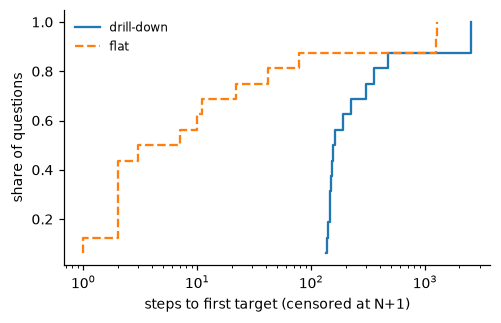

In [17]:
fig, ax = plt.subplots(figsize=(5, 3))
for res, lab, st in ((HIER, "drill-down", "-"), (FLAT, "flat", "--")):
    s = np.sort([r["steps_first"] for r in res.values() if "steps_first" in r])
    ax.step(s, np.arange(1, len(s) + 1) / len(s), st, where="post", label=lab)
ax.set_xscale("log"); ax.set_xlabel("steps to first target (censored at N+1)"); ax.set_ylabel("share of questions")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG / "t6_steps_ecdf.png"); plt.show()

In [18]:
# Key numbers for §9 (printed so the text can be checked against them)
qa = [q for q in HIER if gt[q]["type"] == "A" and "steps_first" in HIER[q]]
qb = [q for q in HIER if gt[q]["type"] == "B" and "steps_first" in HIER[q]]
print(f"questions with targets: A {len(qa)}, B {len(qb)}")
for name, res in (("drill-down", HIER), ("flat", FLAT)):
    print(f"{name:10s} reached A {sum(res[q]['reached'] for q in qa)}/{len(qa)}, B {sum(res[q]['reached'] for q in qb)}/{len(qb)}; "
          f"median steps_first A {np.median([res[q]['steps_first'] for q in qa]):.1f}, B {np.median([res[q]['steps_first'] for q in qb]):.1f}")
kf = {lv: [] for lv in (0, 1, 2)}
for r in HIER.values():
    for lv in kf:
        sc = [t for t in r["answer"]["trace"] if t["level"] == lv]
        kf[lv].append(sum(t["kept"] for t in sc) / len(sc))
print("kept / frontier per level (mean, min-max):", {f"L{lv}": (round(np.mean(v), 2), round(min(v), 2), round(max(v), 2)) for lv, v in kf.items()})
print("super-nodes scored per question (min-max):", min(r["answer"]["n_scored"] for r in HIER.values()),
      max(r["answer"]["n_scored"] for r in HIER.values()))
miss = [q for q in qa + qb if not HIER[q]["reached"]]
print("drill-down never reaches:", miss, "; of these, targets in a single L0 super-node:", [q for q in miss if D.loc[q, "L0"] == 1])
# evaluator-side diagnostic: the level at which the last super-node holding a target was dropped
for q in miss:
    t, tr = set(GOLD[q]["targets"]), HIER[q]["answer"]["trace"]
    lost = min(x["level"] for x in tr if not x["kept"] and t & set(agent.index(2026).sn[x["id"]]["member_ids"])
               and not any(y["kept"] and y["level"] == x["level"] and t & set(agent.index(2026).sn[y["id"]]["member_ids"]) for y in tr))
    print(f"  {q}: targets dropped at L{lost}")
for name, res in (("drill-down", HIER), ("flat", FLAT)):
    obj = np.mean([(res[q]["methods" if q in qa else "claims"] + res[q]["citations"]) / 2 for q in qa + qb])
    print(f"{name}: selection objective, mean (item + citation hit-rate) / 2 over {len(qa + qb)} questions = {obj:.3f}")
print("flat search needs > 1000 ranks on:", {q: FLAT[q]["steps_first"] for q in qa + qb if FLAT[q]["steps_first"] > 1000},
      "; drill-down on these:", {q: HIER[q]["steps_first"] for q in qa + qb if FLAT[q]["steps_first"] > 1000})
for name, res in (("drill-down", HIER), ("flat", FLAT)):
    print(f"{name}: mean articles cited per answer A {np.mean([len(res[q]['answer']['_articles']) for q in qa]):.1f}, "
          f"B {np.mean([len(res[q]['answer']['_articles']) for q in qb]):.1f} (breadth diagnostic)")
# Sanity checks: the tree's leaves cover every snapshot node of the answer kinds (the steps censor N assumes it),
# and a full beam (every super-node kept) ranks exactly the flat candidate list
S, ix = SNAP[2026], agent.index(2026)
assert all(set(ix.leaves) >= {v for v in S.ids if S.type[v] in KINDS[t]} for t in KINDS)
full = run(Agent(agent.ix, beam=(15, 60, 240)), "hier")
assert all(full[q]["answer"]["ranked"] == FLAT[q]["answer"]["ranked"] for q in full)
print("tree leaves cover all answer-kind nodes; full beam ranks the same list as flat on all 18 questions")

questions with targets: A 12, B 4
drill-down reached A 10/12, B 4/4; median steps_first A 206.5, B 143.0
flat       reached A 12/12, B 4/4; median steps_first A 10.5, B 2.0
kept / frontier per level (mean, min-max): {'L0': (np.float64(0.67), 0.67, 0.67), 'L1': (np.float64(0.47), 0.41, 0.56), 'L2': (np.float64(0.46), 0.4, 0.56)}
super-nodes scored per question (min-max): 133 162
drill-down never reaches: ['Q4', 'Q10'] ; of these, targets in a single L0 super-node: ['Q4', 'Q10']
  Q4: targets dropped at L1
  Q10: targets dropped at L1
drill-down: selection objective, mean (item + citation hit-rate) / 2 over 16 questions = 0.506
flat: selection objective, mean (item + citation hit-rate) / 2 over 16 questions = 0.447
flat search needs > 1000 ranks on: {'Q7': 1266, 'Q10': 1252} ; drill-down on these: {'Q7': 354, 'Q10': 2525}
drill-down: mean articles cited per answer A 13.0, B 4.0 (breadth diagnostic)
flat: mean articles cited per answer A 13.2, B 4.0 (breadth diagnostic)
tree leaves cover 

## 9. Findings, implementation guidelines and future work

### What the POC shows

Numbers are from the cells above, with the selected configuration (keyword overlap, beam (10, 20, 40)). There are 12
type-A and 4 type-B questions with attainable targets. The differences are point estimates on few questions, without
CIs, and the configuration was selected on these questions, so the levels are optimistic (future work).

- **Reach.** The drill-down reaches a GT item on 10 of 12 A questions and on all 4 B questions; flat search reaches one
  on all 16.
- **Accuracy (M1): mixed; the drill-down is close to or above flat search.**
  - Type-A methods: 0.275 vs 0.295.
  - Type-A method claims: 0.250 vs 0.306, on the 9 questions with an attainable method claim.
  - Type-A citations: 0.657 vs 0.578.
  - Type-B claims: 0.740 vs 0.543; type-B citations: 0.438 vs 0.375.
  - Both systems cite about as many articles per answer (A 13.0 vs 13.2, B 4.0 vs 4.0), so the citation differences are
    not a breadth effect between them.
- **Selection objective under §7's scoring:** 0.506 (drill-down) vs 0.447 (flat), mean (item + citation hit-rate) / 2
  over the 16 questions.
- **Precision (M2).** The error rate is 0.042 vs 0.033: both rarely return a listed wrong-domain or outdated method.
- **Cost (M3): flat search is far cheaper on most questions.** The drill-down scores 133–162 super-nodes before its
  first leaf; flat search's median rank to the first item is 10.5 (A) and 2 (B). The exceptions are Q7 and Q10, where
  flat search needs over 1,250 ranks; the drill-down reaches Q7 in 354 steps and misses Q10.
  - Median steps to the first item: A 206.5 vs 10.5; B 143 vs 2.
  - Median steps to 50% of the items: A 413 vs 28.5; B 152.5 vs 6.5.
- **The misses are routing errors at L1.** Q4 and Q10 have all their targets inside a single L0 super-node (§5), which
  the beam keeps; the L1 super-node holding the targets is then dropped.
- **Pruning is spread over the levels.** Kept/frontier is 0.67 at L0, 0.47 at L1 and 0.46 at L2 (D6).
- **Sanity checks pass.** The tree's leaves cover every node of the answer kinds, and a full beam (15, 60, 240)
  ranks the same list as flat search; the leakage guard and the ≤2020 temporal check (§6) pass.

With the selected configuration, the drill-down matches or beats flat search on type-B claims and on citations, and
is slightly behind on type-A methods and method claims. It pays for this with about 130–160 super-node scores per
question, so flat search reaches its first target in far fewer steps. On these questions, the hierarchy acts as a filter that
can sharpen the answer list, not as a shortcut to the first target.

### Guidelines for the implementation

1. **Modules:**
   - `tkh/retrieve.py`: the agent only (§6); it sees `(question, type)`;
   - `eval/retrieval.py`: gold resolution (§4) and the metrics M1–M3 (§7);
   - CLI `python -m eval retrieval --run out`, writing `metrics.json["retrieval"]` and `out/retrieval_answers.json`;
   - in `make all` (offline, seconds).
2. **Gold resolution (evaluator):**
   - methods by exact name/alias or acronym, over the answer kinds of type A;
   - citations by author set + year ±1 + hint; each `;`-separated part of an evidence source resolved on its own;
   - type-B sources by DOI, then title;
   - method claims attainable only with a graph claim from the evidence article on the method;
   - report ceilings with every hit-rate.
3. **Agent:** the snapshot rule (D1), snapshot-only node text with the presenting paper's claims (D4), keyword
   overlap fitted per snapshot (D5), the label + centroid blend, beam (10, 20, 40) and the template-stripped question (D6), k = 10, the flat baseline with the same scorer (D7), answers in the GT format with
   node and article ids (D8).
4. **`metrics.json["retrieval"]`:** per question type and system, the mean hit-rates (methods, method claims, claims,
   citations), the mean error rate, reach, the median steps to the first and to 50% of the items, the paired
   differences and the ceilings. Per-question rows and the drill-down traces go to `out/retrieval_answers.json`.
5. **Tests:**
   - a later edge never reaches an earlier snapshot's text or vocabulary (the §6 check);
   - the leakage guard (§8);
   - the tree's leaves cover every node of the answer kinds, and a full beam (15, 60, 240) ranks the same list as
     flat search (§8);
   - gold resolution on fixed examples (GAP by acronym, an `et al.` citation, a `;`-joined evidence source).

### Assumptions, simplifications and directions for future work

**Assumptions** made by the POC, each a check for future work:
- A node matched by exact name or acronym is the method the GT means.
- A graph claim from a claim's source article supports the GT claim (source match, not content match).
- An ambiguous citation counts as hit if any of its candidate articles is cited.
- "By Feb 2026" is answered from the ≤2026 snapshot, which also holds papers published later in 2026.
- Aliases, which carry no date in the export, do not leak later information into earlier snapshots.
- Lexical similarity is an adequate proxy for meaning; it partly overlaps the names used for clustering (D5).
- L2 super-nodes carry no label, so L2 routing relies on the member centroid alone.
- Author order is absent from the export, so citations match by author set.
- The configuration selected on the 18 questions (D5, D6) generalises to new questions.
- The 18 questions represent the intended use; all of them are answered from the ≤2026 snapshot, so retrieval on
  earlier snapshots is untested beyond the §6 check.

**Simplifications**, each a direction for future work:
- **Matching:** a looser method rule (prefix, version-aware) for names such as "Orb" → "Orb-v2", reported as a
  separate tier.
- **Per-claim matching:** each GT method claim matched to its own evidence source, not to the union of the method's
  sources.
- **Claim content:** a semantic judge (e.g. an LLM entailment check) to match GT claim text and evidence against the
  returned claims, with `distractor_note` as negative checks and a shuffled-answer control.
- **Multi-source claims:** a strict tier requiring every source of a claim, informed by `independence`.
- **Stratification:** hit-rates by `coverage` and `evidence_type`; contrast sources (`contrast_sources`) scored
  separately.
- **Citation breadth control:** articles cited and citation precision, since citation hit-rate rises with breadth
  alone.
- **Temporal compliance:** the share of cited articles dated within the GT `as_of`, and a snapshot check against the
  evaluator's date.
- **Budget-matched recall:** recall at an equal number of inspected nodes, with its area under the curve.
- **Null models (a validity criterion of the brief, stated for coherence):** a size-preserving random tree, to test whether the grouping helps beyond
  chance; a label-free ablation, to isolate the contribution of the labels.
- **Statistics (a validity criterion of the brief, stated for stability):** paired bootstrap CIs over questions for every difference.
- **Held-out validation of the configuration:** re-select under leave-one-question-out, or on new questions, and
  report the held-out hit-rates and steps beside the in-sample ones.
- **Routing:** a beam that adapts to the frontier or to the score distribution; embeddings for paraphrase; better
  L1 routing for questions whose targets are pruned (§8).
- **Questions on earlier snapshots,** to test the temporal dimension of retrieval.
- **Worked traces** in the report: one success and one L1 routing failure (Q4 or Q10), read from the drill-down trace.